In [39]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
 

In [40]:
df = pd.read_csv("placement.csv")
df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


In [41]:
df.sample(5)

,cgpa,placement_exam_marks,placed
998,8.62,46.0,1
9,7.75,94.0,1
491,7.77,49.0,1
765,6.55,28.0,0
390,6.63,16.0,1


C:\Users\visha\AppData\Local\Temp\ipykernel_17708\2028494705.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['cgpa'])
C:\Users\visha\AppData\Local\Temp\ipykernel_17708\2028494705.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['placement_exam_marks'])


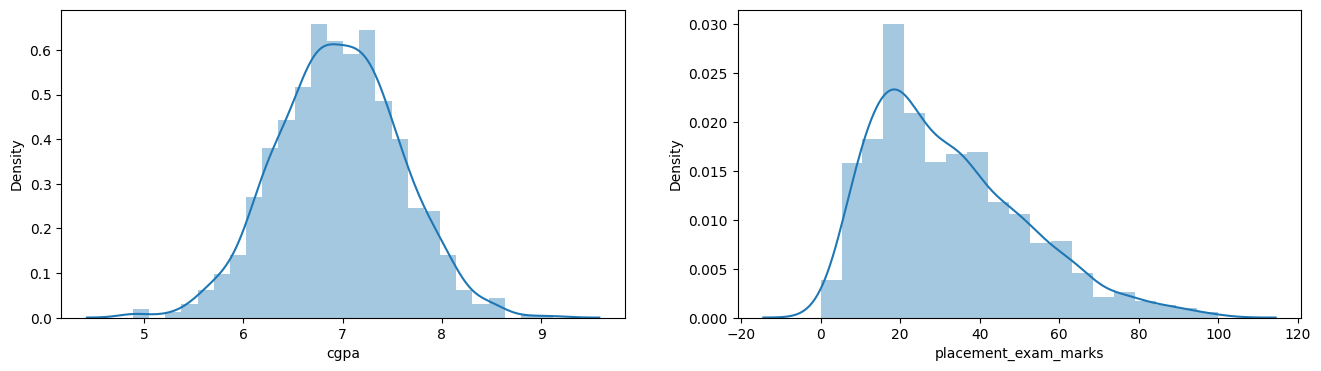

In [42]:
plt.figure(figsize=(16,4))
plt.subplot(1,2,1)
sns.distplot(df['cgpa']) 

plt.subplot(1,2,2)
sns.distplot(df['placement_exam_marks'])

plt.show()

In [43]:
df['placement_exam_marks'].describe()

count    1000.000000
mean       32.225000
std        19.130822
min         0.000000
25%        17.000000
50%        28.000000
75%        44.000000
max       100.000000
Name: placement_exam_marks, dtype: float64

<Axes: ylabel='placement_exam_marks'>

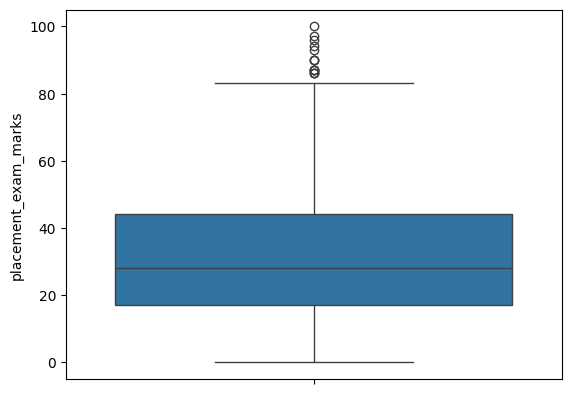

In [44]:
sns.boxplot(df['placement_exam_marks'])

In [45]:
# finding the IQR 

percentile25 = df['placement_exam_marks'].quantile(0.25)
percentile75 = df['placement_exam_marks'].quantile(0.75)

In [46]:
percentile75

np.float64(44.0)

In [47]:
iqr = percentile75 - percentile25

In [48]:
iqr

np.float64(27.0)

In [49]:
upper_limit = percentile75 + 1.5 * iqr
lower_limit = percentile25 - 1.5 * iqr 

In [50]:
print("upper limit :", upper_limit)
print("lower_limit :", lower_limit)

upper limit : 84.5
lower_limit : -23.5


# finding outliers 

In [51]:
df[df['placement_exam_marks'] > upper_limit]

,cgpa,placement_exam_marks,placed
9,7.75,94.0,1
40,6.60,86.0,1
61,7.51,86.0,0
134,6.33,93.0,0
162,7.80,90.0,0
283,7.09,87.0,0
290,8.38,87.0,0
311,6.97,87.0,1
324,6.64,90.0,0
630,6.56,96.0,1


In [52]:
df[df['placement_exam_marks'] > lower_limit]

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
998,8.62,46.0,1


# trimming 

In [53]:
new_df = df[df['placement_exam_marks'] < upper_limit]

In [54]:
new_df.shape

(985, 3)

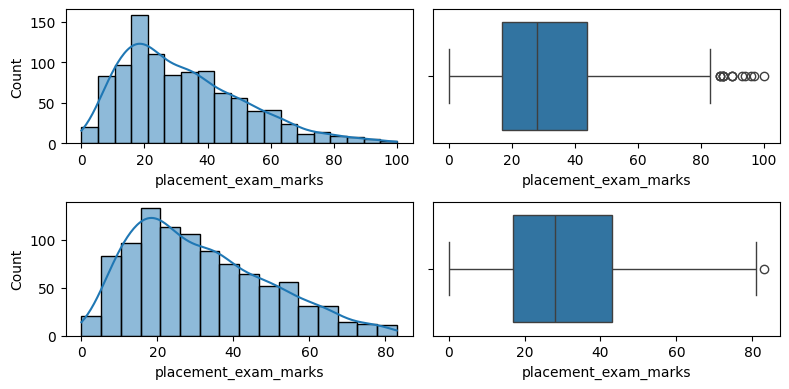

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))

plt.subplot(2, 2, 1)
sns.histplot(df['placement_exam_marks'], kde=True)

plt.subplot(2, 2, 2)
sns.boxplot(x=df['placement_exam_marks'])

plt.subplot(2, 2, 3)
sns.histplot(new_df['placement_exam_marks'], kde=True)

plt.subplot(2, 2, 4)
sns.boxplot(x=new_df['placement_exam_marks'])

plt.tight_layout()
plt.show()

# capping 

# np.where function me 

is me  3 condition hoti hai 
1. condition 
2. agar condition sahi hai ou upper limit ko us values ko replace kar dena hai 
3. nahi to agar us column ka lower limit ka value loweer value se kam hai to us value o lower limit ke replace kar denge 
4. agar dono values sahi nhi hai to us valuse ko astish (wase hi rahne denge)

In [56]:
new_df_cap = df.copy()

new_df_cap['placement_exam_marks']  = np.where(
    new_df_cap['placement_exam_marks'] > upper_limit,
    upper_limit,
    np.where(
        new_df_cap['placement_exam_marks'] < lower_limit,
        lower_limit,
        new_df_cap['placement_exam_marks']
    )
)

In [57]:
new_df_cap.shape

(1000, 3)

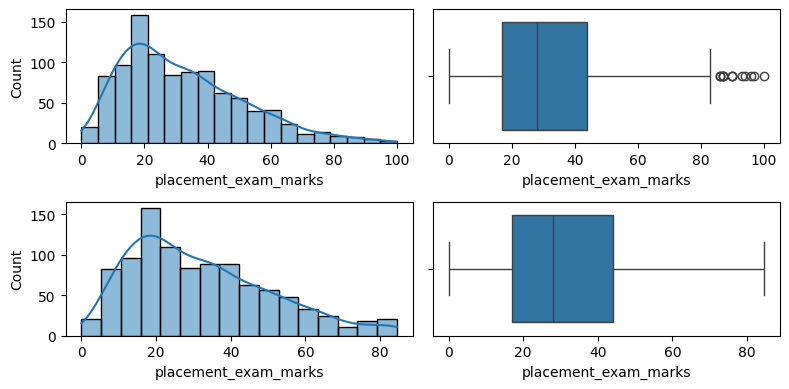

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))

plt.subplot(2, 2, 1)
sns.histplot(df['placement_exam_marks'], kde=True)

plt.subplot(2, 2, 2)
sns.boxplot(x=df['placement_exam_marks'])

plt.subplot(2, 2, 3)
sns.histplot(new_df_cap['placement_exam_marks'], kde=True)

plt.subplot(2, 2, 4)
sns.boxplot(x=new_df_cap['placement_exam_marks'])

plt.tight_layout()
plt.show()

In [61]:
outliers = df[(df['placement_exam_marks'] < lower_limit) | (df['placement_exam_marks'] > upper_limit)]
print("Outliers:\n", outliers)


Outliers:
      cgpa  placement_exam_marks  placed
9    7.75                  94.0       1
40   6.60                  86.0       1
61   7.51                  86.0       0
134  6.33                  93.0       0
162  7.80                  90.0       0
283  7.09                  87.0       0
290  8.38                  87.0       0
311  6.97                  87.0       1
324  6.64                  90.0       0
630  6.56                  96.0       1
685  6.05                  87.0       1
730  6.14                  90.0       1
771  7.31                  86.0       1
846  6.99                  97.0       0
917  5.95                 100.0       0
